# LightGBM modeluaren entrenamendua

### 1. Liburutegien inportazioa eta karga

In [3]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path("../scoring").resolve()))  # cnc_ml eta app inportatu ahal izateko
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    confusion_matrix,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
import lightgbm as lgb
from lightgbm import LGBMClassifier

from cnc_ml.columns import FAILURE_SUBTYPES, MACHINE_TYPES, RAW_FEATURES, TARGET
from cnc_ml.pipeline import build_pipeline
from app.services.model import FAILURE_THRESHOLD
import importlib
import app.services.model as m
importlib.reload(m)

df = pd.read_csv("../data/ai4i2020_train.csv")
print( df.shape)


(8000, 13)


### 2.Datuen azterketa

In [4]:
delete_cols = [
    "machine_id",
    "failure_TWF", "failure_HDF", "failure_PWF", "failure_OSF", "failure_RNF",
]

X = df.drop(columns=delete_cols + [TARGET])
y = df[TARGET]

# Ereduak zenbakiak bakarrik ulertzen ditu. machine_type testua da (L, M, H) =  kalitate baxua, ertaina, altua. Ordena naturala duenez, 0, 1, 2 bihurtzen dugu.
X["machine_type"] = X["machine_type"].map({"L": 0, "M": 1, "H": 2})

# Feature engineering: zentzu fisikoa duten zutabe berriak sortu.

X["temp_diff_K"] = X["process_temp_K"] - X["air_temp_K"]            # bero-xahutzea
X["power_W"] = X["torque_Nm"] * X["rpm"] * 2 * math.pi / 60         # potentzia mekanikoa
X["wear_torque"] = X["tool_wear_min"] * X["torque_Nm"]              # gainkarga

print("\nEreduak erabiliko dituen feature-ak:", list(X.columns))


Ereduak erabiliko dituen feature-ak: ['machine_type', 'air_temp_K', 'process_temp_K', 'rpm', 'torque_Nm', 'tool_wear_min', 'temp_diff_K', 'power_W', 'wear_torque']


### 3. TRAIN / BALIOZTAPENA / TEST ZATITAN BANATU

In [5]:
# - train:        ereduak honekin ikasten du
# - balioztapena: noiz gelditu erabakitzeko (early stopping)
# - test:         AMAIERAN bakarrik erabiltzen da, benetako nota jakiteko. Inoiz ez doitzeko.
#
# stratify=y   -> hutsegiteen % bera mantentzen du zati bakoitzean (garrantzitsua hutsegite gutxirekin)
# random_state -> emaitza beti bera izan dadin eta errepika daitekeen
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.20, stratify=y_temp, random_state=42
)
print(f"\nTrain: {len(X_train)}  |  Balioztapena: {len(X_val)}  |  Test: {len(X_test)}")


Train: 5120  |  Balioztapena: 1280  |  Test: 1600


### 4. EREDUA SORTU

In [6]:
# LightGBM-k XGBoost-en ideia bera erabiltzen du (boosting: zuhaitz txiki asko,
# bakoitzak aurrekoen akatsak zuzentzen ditu). Desberdintasun nagusiak:
#   - Azkarragoa da, batez ere datu askorekin (histogramak erabiltzen ditu).
#   - Zuhaitzak "hostoz hosto" hazten ditu (leaf-wise): beti akats handiena duen
#     hostoa zatitzen du. XGBoost-ek "mailaz maila" egiten du (level-wise).
#     Horregatik, LightGBM-n konplexutasuna num_leaves-ekin kontrolatzen da,
#     ez hainbeste max_depth-ekin.

# XGBoost-en bezala: hutsegite bakoitzak pisu handiagoa izan dezan (~30 hemen).
hutsegite_pisua = (y_train == 0).sum() / (y_train == 1).sum()

eredua = LGBMClassifier(
    n_estimators=1000,        # zuhaitz kopuru MAXIMOA (early stopping-ek lehenago geldituko du)
    learning_rate=0.05,       # zuhaitz bakoitzak zenbat ekartzen duen (XGBoost-en berdina)
    num_leaves=15,            # zuhaitz bakoitzeko hosto kopuru maximoa. PARAMETRO NAGUSIA.
                              # max_depth=4 duen zuhaitz batek gehienez 16 hosto ditu, beraz 15 antzekoa da
    max_depth=-1,             # -1 = mugarik gabe (num_leaves-ek mugatzen du jada)
    min_child_samples=20,     # hosto batean gutxieneko errenkada kopurua; igotzeak kontserbadoreagoa egiten du
    subsample=0.8,            # zuhaitz bakoitzak errenkaden % 80 ikusten du...
    subsample_freq=1,         # ...KONTUZ: hau gabe subsample-k EZ du ezer egiten LightGBM-n
    colsample_bytree=0.8,     # zuhaitz bakoitzak zutabeen % 80 ikusten du
    scale_pos_weight=hutsegite_pisua,   # klaseen desoreka konpentsatzen du
    metric="average_precision",         # zaindu beharreko metrika (XGBoost-en "aucpr"-ren baliokidea)
    importance_type="gain",   # garrantzia "gain"-en arabera, XGBoost-ekin konparagarria izan dadin
    random_state=42,
    n_jobs=-1,                # ordenagailuaren nukleo guztiak erabili
    verbose=-1,               # LightGBM-ren barne-mezuak isildu
)


### 5. ENTRENATU

In [7]:
# LightGBM-n early stopping eta inprimaketa "callback" bidez jartzen dira:
#   - early_stopping(50):   balioztapenean 50 zuhaitz jarraian hobetzen ez badu, gelditu
#   - log_evaluation(100):  100 zuhaitzetik behin nola doan inprimatu
eredua.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    callbacks=[
        lgb.early_stopping(stopping_rounds=50),
        lgb.log_evaluation(period=100),
    ],
)
# Kontuz: LightGBM-n best_iteration_ (azpimarrarekin) eta jada 1etik hasita dago
print(f"\nZuhaitz kopuru onena: {eredua.best_iteration_}")

Training until validation scores don't improve for 50 rounds


c:\Users\Admin\Desktop\T1-erronka1\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[100]	valid_0's average_precision: 0.888623
Early stopping, best iteration is:
[66]	valid_0's average_precision: 0.892909

Zuhaitz kopuru onena: 66


### 6. TESTAREKIN EBALUATU

In [8]:
# predict_proba-k klase bakoitzaren probabilitatea itzultzen du; [:, 1] = hutsegite-probabilitatea
hutsegite_prob = eredua.predict_proba(X_test)[:, 1]

# ATALASEAK (umbral) erabakitzen du zein probabilitatetik aurrera esaten dugun "huts egingo du".
# 0.5 da ohikoa, baina hutsegite bat ez detektatzea garestia bada (makina hautsita),
# komeni da jaistea: hutsegite gehiago detektatzen dituzu, alarma faltsu gehiagoren truke.
# (Horregatik jaitsi zenuten 0.15era zuen proiektuan.)
ATALASEA = 0.15
iragarpena = (hutsegite_prob > ATALASEA).astype(int)

print(f"\nROC-AUC: {roc_auc_score(y_test, hutsegite_prob):.3f}   (1 = perfektua, 0.5 = zoria)")

print(f"\nTxostena {ATALASEA} atalasearekin:")
# precision: ematen dituen alarmetatik, zenbat ziren benetako hutsegiteak
# recall:    benetako hutsegiteetatik, zenbat detektatzen dituen  <- hemen garrantzitsuena
print(classification_report(y_test, iragarpena, target_names=["OK", "Hutsegitea"]))

# Nahasmen-matrizea:
#                     OK iragarri    Hutsegitea iragarri
#   benetan OK         [  TN              FP  ]   FP = alarma faltsua
#   benetan hutsegitea [  FN              TP  ]   FN = detektatu GABEKO hutsegitea (txarrena)
print("Nahasmen-matrizea:")
print(confusion_matrix(y_test, iragarpena))


ROC-AUC: 0.978   (1 = perfektua, 0.5 = zoria)

Txostena 0.15 atalasearekin:
              precision    recall  f1-score   support

          OK       1.00      0.94      0.97      1546
  Hutsegitea       0.36      0.93      0.52        54

    accuracy                           0.94      1600
   macro avg       0.68      0.93      0.74      1600
weighted avg       0.98      0.94      0.95      1600

Nahasmen-matrizea:
[[1456   90]
 [   4   50]]


### 8. GRAFIKOAK ETA ATALASE-PROBAK

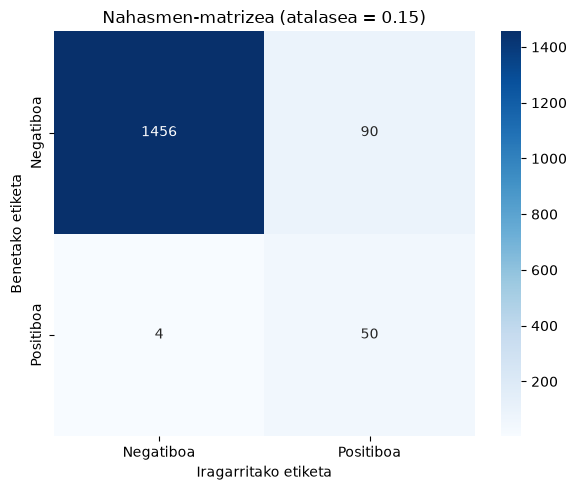


Atalasea | Negatibo faltsuak | Positibo faltsuak | Recall | Precision
----------------------------------------------------------------------
0.5      |                10 |                12 |   0.81 |      0.79
0.45     |                10 |                14 |   0.81 |      0.76
0.4      |                10 |                21 |   0.81 |      0.68
0.35     |                 9 |                32 |   0.83 |      0.58
0.3      |                 9 |                50 |   0.83 |      0.47
0.25     |                 7 |                61 |   0.87 |      0.44
0.2      |                 7 |                74 |   0.87 |      0.39
0.15     |                 4 |                90 |   0.93 |      0.36
0.1      |                 3 |               122 |   0.94 |      0.29


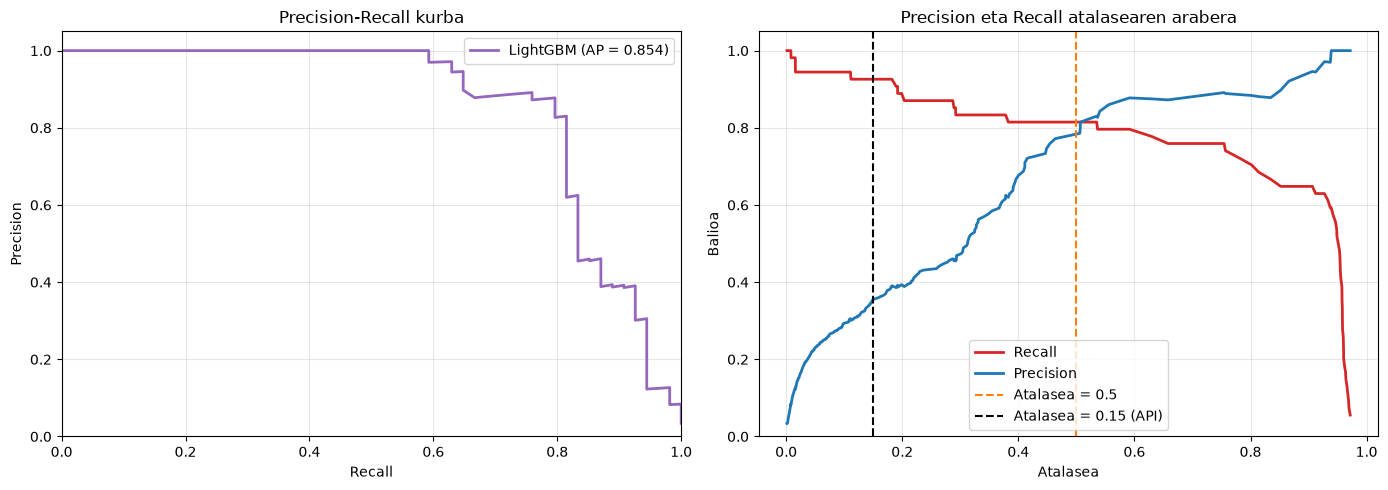


Kostu txikiena: 51,000 € (atalasea = 0.18)
Eredurik gabe (hutsegite guztiak FN): 270,000 €


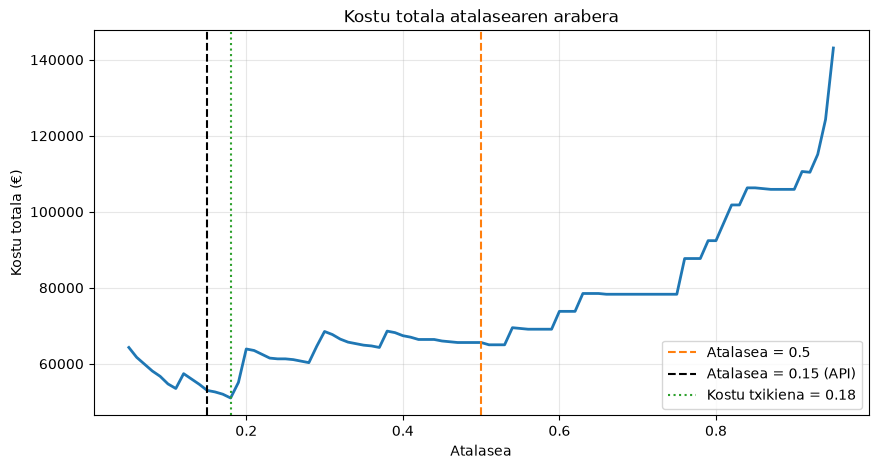

In [9]:
# Hemendik aurrera TEST zatiarekin lan egiten da (6. atalean bezala).
# Izen laburrak, grafikoen kodea irakurterrazagoa izan dadin:
y_eval = y_test             # benetako etiketak
y_proba = hutsegite_prob    # ereduaren hutsegite-probabilitatea
y_pred = iragarpena         # ATALASEA-rekin lortutako iragarpena (0/1)


# --- 8.1 Nahasmen-matrizea (heatmap) ---
nahasketa = confusion_matrix(y_eval, y_pred)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(nahasketa, annot=True, fmt="d", cmap="Blues", ax=ax,
            xticklabels=["Negatiboa", "Positiboa"],
            yticklabels=["Negatiboa", "Positiboa"])
ax.set_ylabel("Benetako etiketa")
ax.set_xlabel("Iragarritako etiketa")
ax.set_title(f"Nahasmen-matrizea (atalasea = {ATALASEA})")
plt.tight_layout()
plt.show()

 # --- 8.4 Atalase desberdinekin proba (taula) ---
print("\nAtalasea | Negatibo faltsuak | Positibo faltsuak | Recall | Precision")
print("-" * 70)
for atalasea in [0.5, 0.45, 0.4, 0.35, 0.3, 0.25, 0.2, 0.15, 0.1]:
    pred = (y_proba > atalasea).astype(int)
    fn = ((pred == 0) & (y_eval == 1)).sum()
    fp = ((pred == 1) & (y_eval == 0)).sum()
    rec = recall_score(y_eval, pred)
    prec = precision_score(y_eval, pred, zero_division=0)
    print(f"{atalasea:<8} | {fn:>17} | {fp:>17} | {rec:>6.2f} | {prec:>9.2f}")

# --- 8.2 Precision vs Recall ---
precision, recall, atalase_kurba = precision_recall_curve(y_eval, y_proba)
ap = average_precision_score(y_eval, y_proba)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))   # 1 errenkada, 2 grafiko

# 1. grafikoa: precision-recall kurba
ax = axes[0]
ax.plot(recall, precision, lw=2, color="tab:purple", label=f"LightGBM (AP = {ap:.3f})")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-Recall kurba")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(alpha=0.3)

# 2. grafikoa: precision eta recall atalasearen arabera
# (precision eta recall-ek atalaseak baino balio 1 gehiago dute, horregatik [:-1])
ax = axes[1]
ax.plot(atalase_kurba, recall[:-1], lw=2, color="tab:red", label="Recall")
ax.plot(atalase_kurba, precision[:-1], lw=2, color="tab:blue", label="Precision")
ax.axvline(0.5, color="tab:orange", ls="--", label="Atalasea = 0.5")
ax.axvline(ATALASEA, color="black", ls="--", label=f"Atalasea = {ATALASEA} (API)")
ax.set_xlabel("Atalasea")
ax.set_ylabel("Balioa")
ax.set_title("Precision eta Recall atalasearen arabera")
ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# --- 8.3 Kostua atalasearen arabera ---
# Kostu-taula ofiziala (€): FN = detektatu gabeko hutsegitea, FP = alarma faltsua...
C_FN, C_FP, C_TP, C_TN = 5000, 200, 300, 0

atalaseak = np.round(np.arange(0.05, 0.96, 0.01), 2)
kostuak = []
for u in atalaseak:
    pred = (y_proba > u).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_eval, pred).ravel()
    kostuak.append(C_FN * fn + C_FP * fp + C_TP * tp + C_TN * tn)

onena = atalaseak[np.argmin(kostuak)]
print(f"\nKostu txikiena: {min(kostuak):,} € (atalasea = {onena})")
print(f"Eredurik gabe (hutsegite guztiak FN): {C_FN * y_eval.sum():,} €")

plt.figure(figsize=(10, 5))
plt.plot(atalaseak, kostuak, lw=2)
plt.axvline(0.5, color="tab:orange", ls="--", label="Atalasea = 0.5")
plt.axvline(ATALASEA, color="black", ls="--", label=f"Atalasea = {ATALASEA} (API)")
plt.axvline(onena, color="tab:green", ls=":", label=f"Kostu txikiena = {onena}")
plt.xlabel("Atalasea")
plt.ylabel("Kostu totala (€)")
plt.title("Kostu totala atalasearen arabera")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


